## Preliminaries

Samplewise experiments with **Pixel Flipping** w.r.t. segmentation masks.

In [27]:
import sys
sys.path.append('./tf-explain/')
sys.path.append('./wingbeats/')
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import time
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from wingbeats import modelling as wm # for building simple classifiers
from wingbeats import xai as wx

from tf_explain.core.vanilla_gradients import VanillaGradients
from tf_explain.core.gradients_inputs import GradientsInputs
from tf_explain.core.integrated_gradients import IntegratedGradients

In [28]:
use_mini_dataset   = True
compress_B_lucorum = True
bees_subfolder = '22_species/' if compress_B_lucorum else '25_species/'

dataset_folder = 'Bees_Christian/' if use_mini_dataset else 'Bees/'
metafolder = './beexplainable/metafiles/'

BEES_PATH = '../data/data_lstudio/' + dataset_folder
BEES_MASKS_PATH = '../data/Wildbienen/' + dataset_folder[:-1] + '_masks/Whole/'
IMAGES_PATH = metafolder + dataset_folder + 'images.txt'
MASKS_PATH = metafolder + dataset_folder + 'masks.txt'
IMAGES_LABELS_PATH = metafolder + dataset_folder + bees_subfolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + dataset_folder + bees_subfolder + 'classes.txt'

W_H_PATH = metafolder + dataset_folder + 'widths_heights.txt'
BBOX_PATH = metafolder + dataset_folder + 'bounding_boxes.txt'
PART_CONTOURS = metafolder + dataset_folder + 'part_contours.npy'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/pf_mcd_examples/'

## Load images

In [29]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids = list( img_dict.keys() )
y_true   = list( img_label_dict.values() )
y_true   = np.asarray(y_true, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0

# Read class names
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )

In [30]:
batch_size = 64
img_height = img_width = 224
crop_to_bbox = False # whether to crop image to bbox
overlay_mask = False # whether to segment object and hide background

In [31]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image_and_mask(file_id, img_lookup, img_width, img_height,
                                                                  BEES_PATH, BEES_MASKS_PATH),
                                          label)

In [32]:
# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids, y_true, parse_image_lab)
test_set = test_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images (first item in the tuples, second is the mask)
normalization_layer = Rescaling(1./255)
test_set = test_set.map(lambda x, y: ((normalization_layer(x[0]), x[1]), y))

In [33]:
for image_mask_batch, labels_batch in test_set.take(1):
    print(image_mask_batch[0].shape)
    print(image_mask_batch[1].shape)
    print(labels_batch[0])

(64, 224, 224, 3)
(64, 224, 224, 1)
tf.Tensor(0, shape=(), dtype=uint8)


2024-04-11 16:04:17.232607: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


2024-04-11 16:04:18.463195: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


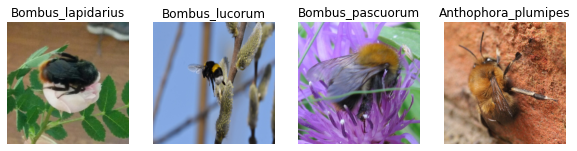

In [34]:
plt.figure(figsize = (10, 10))
num_cols = min(4, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[0][i])
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

2024-04-11 16:04:19.604268: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


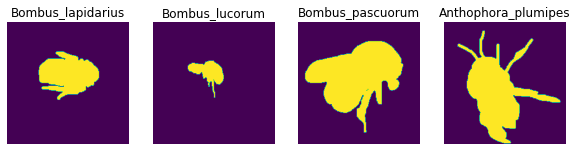

In [35]:
plt.figure(figsize = (10, 10))
num_cols = min(4, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[1][i])
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

## Load Model

In [36]:
# Define model parameters
in_shape = (img_width, img_height, 3)
drop_rate, lr, reg = 0.5, 1e-4, 1e-4

constructor, out_shape =  wm.build_simple_classifier, len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
dataset_type = 'all' # model was trained on whole dataset and is now tested on mini dataset
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_raw' # model was trained on raw whole dataset
weights_file = MODELS_PATH + dataset_type + '/' + bees_subfolder + model_name + '/' + model_name + '.h5' # path to load weights from
print('Model loaded from ' + weights_file)

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

Model loaded from ./beexplainable/models/all/22_species/ResNet50_iNat_raw/ResNet50_iNat_raw.h5


In [37]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(weights_file)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

2024-04-11 16:04:24.455557: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


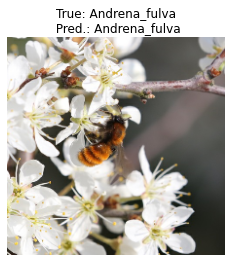

In [38]:
# Pick a correctly predicted image
counts, max_it = 0, 2 # how many hits to find
for img_mask, y_true in test_set.unbatch():
    # Predict class of example
    img, mask = img_mask
    preds = model.predict(np.expand_dims(img, axis = 0))
    if preds[0][y_true] < 0.8: # pick a hard example i.e. < 0.7
        y_pred = np.argmax(preds)

        if y_pred == y_true:
            counts += 1
            if counts == max_it: break

plt.imshow(img)
plt.title('True: ' + classes[y_true] + '\n Pred.: ' + classes[y_pred])
plt.axis('off')
plt.show()

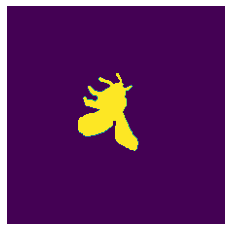

In [39]:
# Flipped pixels will be chosen from within the mask
plt.imshow(mask)
plt.axis('off')
plt.show()

In [40]:
# Compute explanation w.r.t. true or predicted class
explain_true = True # True = explain w.r.t. true label, False = w.r.t. predicted label
explainers = [VanillaGradients(), GradientsInputs(), IntegratedGradients()]
expl_names = ['Gradient', 'Input x Gradient', 'Integrated Gradients']
q = [0.05, 0.25, 0.5, 0.75, 0.95] # quantiles

2024-04-11 16:04:25.589407: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


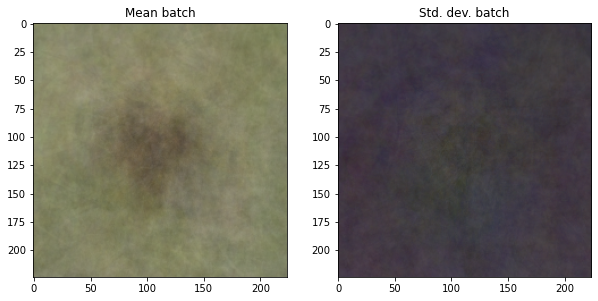

In [41]:
# Compute mean img and std img for one batch in test set
for img_mask_batch, lab_batch in test_set.take(1):
    mean_img = tf.math.reduce_mean(img_mask_batch[0], axis = 0)
    std_img  = tf.math.reduce_std(img_mask_batch[0],  axis = 0)

plt.figure(figsize = (10, 5))
plt.subplot(121)
plt.imshow(mean_img)
plt.title('Mean batch')

plt.subplot(122)
plt.imshow(std_img)
plt.title('Std. dev. batch')
plt.show()

### PF according to Mask

In [16]:
# Flipping parameters
percent_to_flip = 0.75
percent_step = 0.05
percents = int(percent_to_flip*100)
num_scores = int(percent_to_flip / percent_step) + 1
total_k = int( np.count_nonzero(mask) * percent_to_flip ) # max. number of pixels to deactivate
step_k  = int( np.count_nonzero(mask) * percent_step )    # batch size of flipped pixels

In [17]:
flat_mask = mask.numpy().flatten()
top_ind = np.argsort(flat_mask)[-total_k : ] # first total_k pixels with highest gradients
flat_mask.shape

(50176,)

In [18]:
# Dictionary of (all pixel-flipped) heatmaps and quantile maps for every xai method
heatmaps = {e: [] for e in expl_names}
qmaps    = {}

In [19]:
# Apply pixel flipping
img_flip = img.numpy()
start_time = time.time()
for k in range(0, total_k - total_k%step_k, step_k): # loop through pixel batches
    for i in range(k, k + step_k): # loop through current batch
        # Set pixels to a random value drawn from the normal distribution at position (ind_i, ind_j)
        ind_i = top_ind[i] // img_width # y coord. from flat indexes
        ind_j = top_ind[i] % img_width  # x coord.
        img_flip[ind_i, ind_j, :] = np.random.normal(mean_img[ind_i, ind_j], std_img[ind_i, ind_j])

    for i in range(len(explainers)): # Note: tf-explain removes softmax itself
        heatmaps[expl_names[i]].append( explainers[i].explain((np.array([img_flip]), None),
                                                              model, y_true.numpy(),
                                                              norm = "min_max") )
print("--- %s seconds ---" % (time.time() - start_time))

--- 4.721776247024536 seconds ---


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


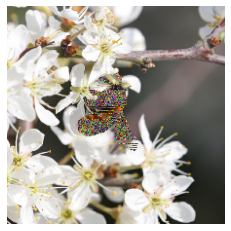

In [20]:
# Inspect fully flipped image
plt.imshow(img_flip)
plt.axis('off')
plt.show()

In [21]:
# Compute quantile maps
start_time = time.time()
for exp in expl_names:
    qmaps[exp] = wx.quantile_maps(heatmaps[exp], q)
print("--- %s seconds ---" % (time.time() - start_time))

--- 21.34682321548462 seconds ---


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


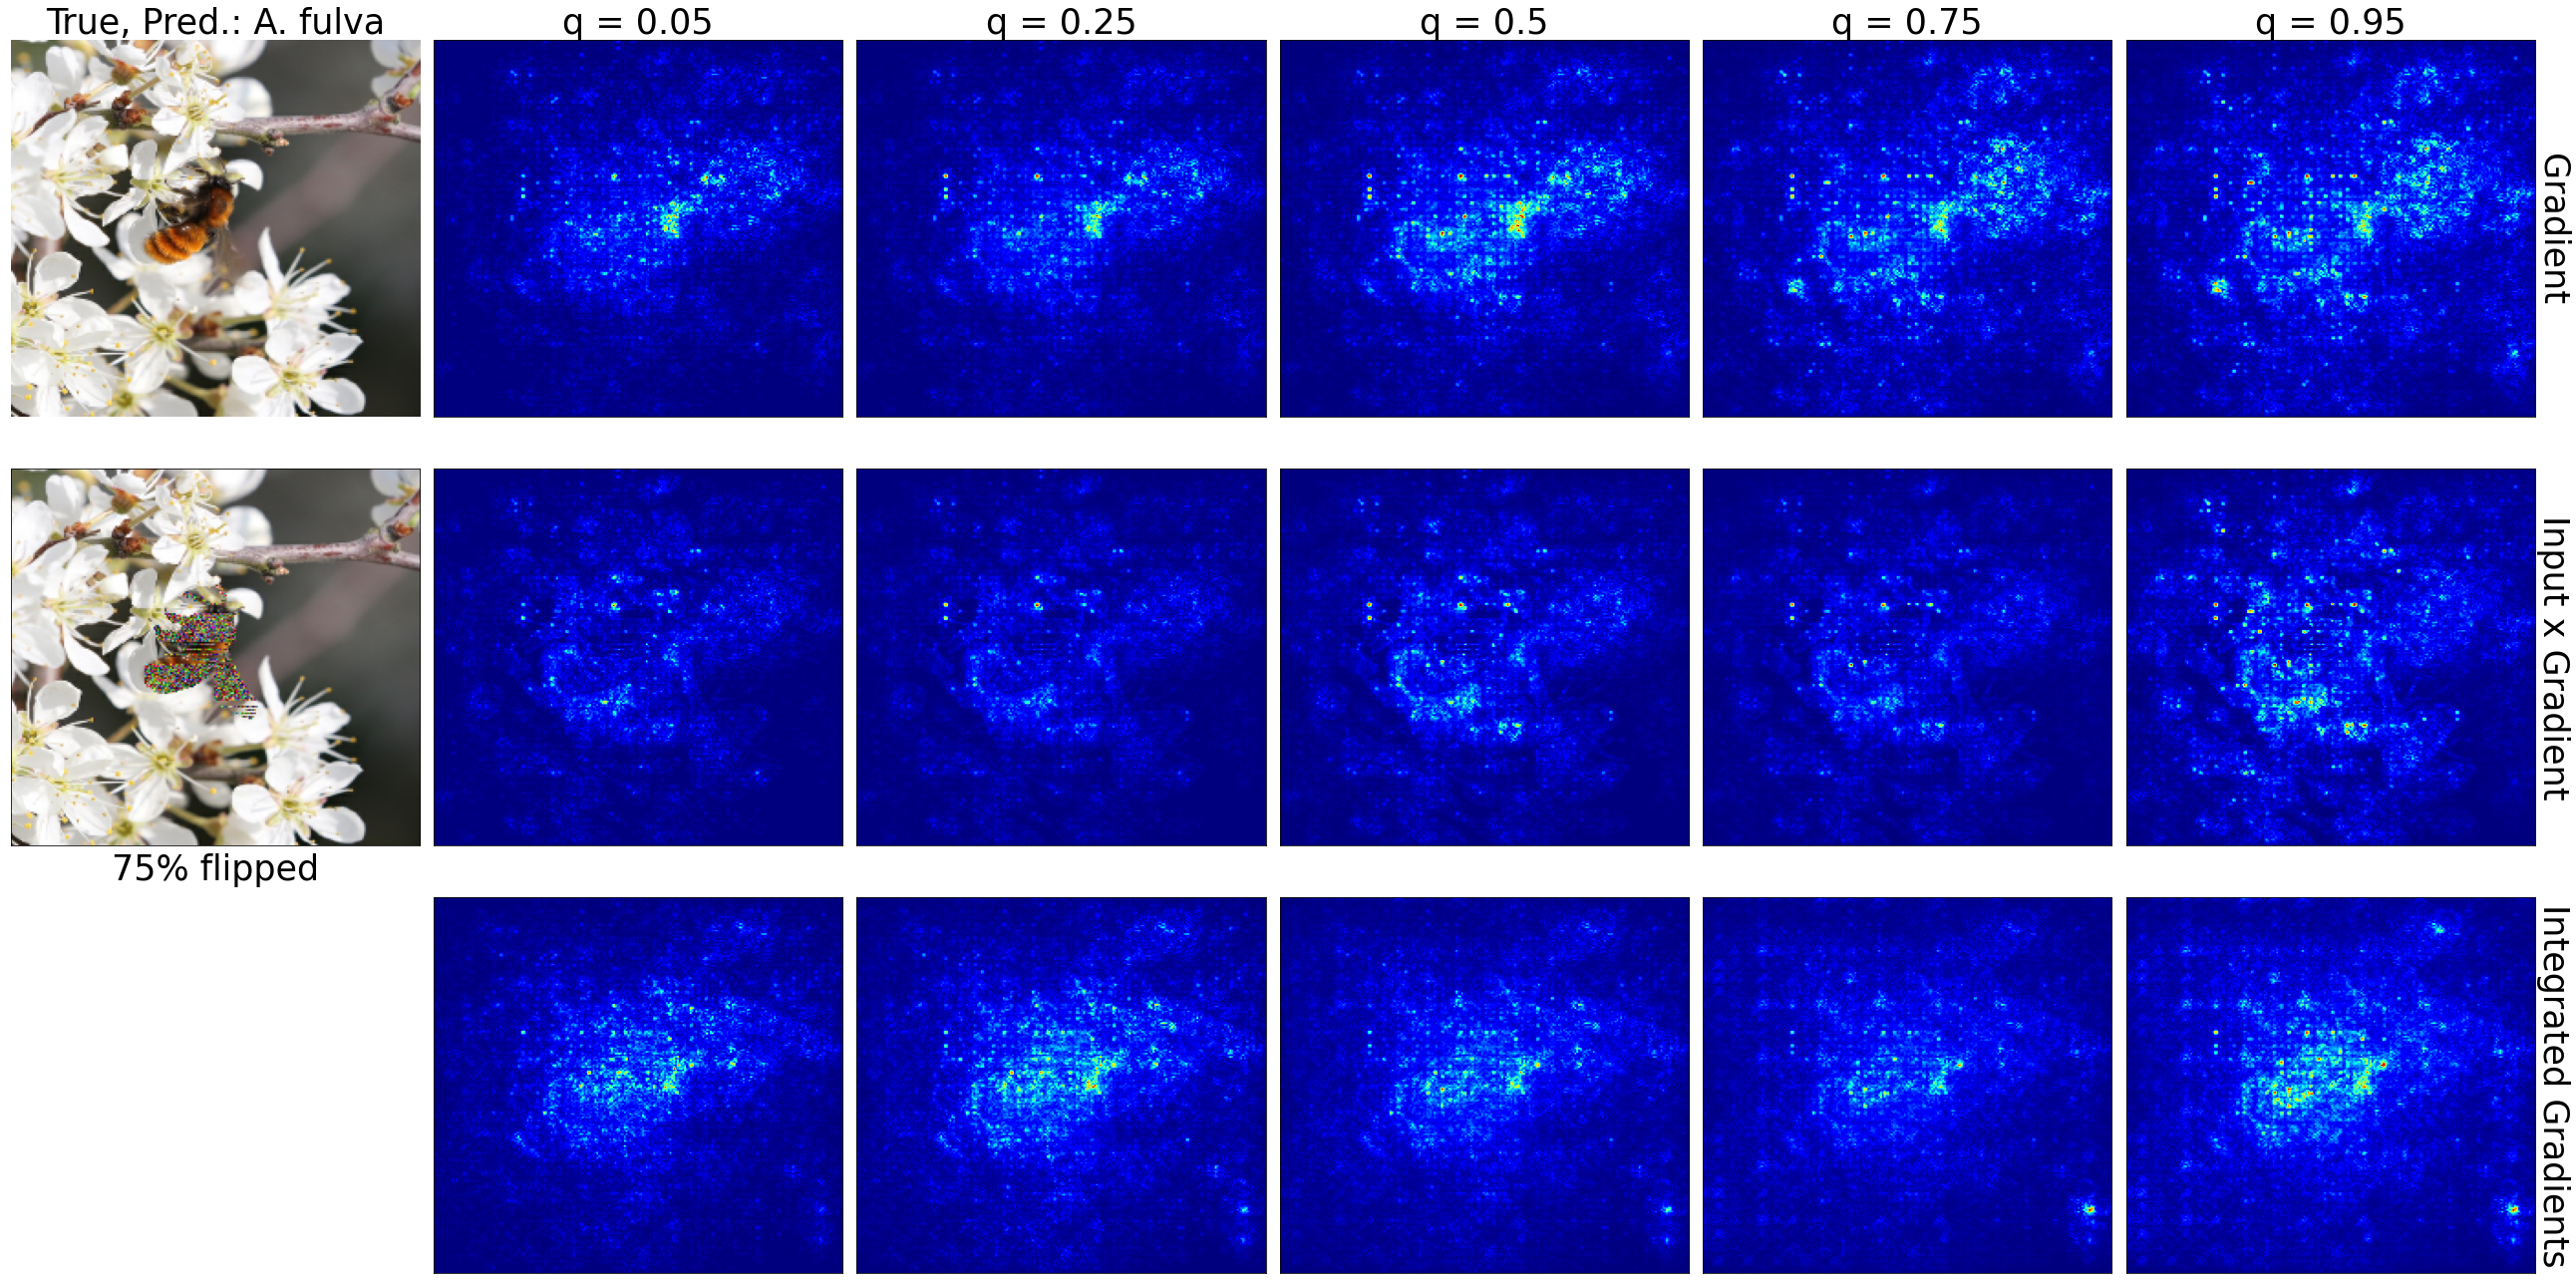

In [22]:
num_cols, num_rows = len(q)+1, len(explainers)
title_size, ticks_size = 35, 35

fig = plt.figure(figsize = (6 * num_cols, 6 * num_rows))

plt.subplot(num_rows, num_cols, 1)
plt.imshow(img, aspect = 'auto')
gen, spec = classes[y_pred].split('_')
title_label = gen[0] + '. ' + spec
plt.title('True, Pred.: ' + title_label, fontsize = title_size)
plt.axis('off')

plt.subplot(num_rows, num_cols, len(q)+2)
plt.imshow(img_flip, aspect = 'auto')
plt.xlabel(str(percents) + '% flipped', fontsize = title_size)
plt.xticks([]);plt.yticks([])

for i in range(num_rows):
    for j in range(num_cols-1):
        ax = plt.subplot(num_rows, num_cols, j+i*num_cols+2)
        plt.imshow(qmaps[expl_names[i]][j], cmap='jet', aspect='auto')
        if i == 0:
            plt.title('q = ' + str(q[j]), fontsize = title_size)
        plt.xticks([])
        plt.yticks([])
        if j == num_cols-2:
            ax.yaxis.set_label_position("right")
            ax.set_ylabel(expl_names[i], fontsize = ticks_size, rotation = -90, labelpad = 35)

plt.tight_layout()
fig.savefig(FIGURES_PATH + classes[y_pred] + '_qmaps_pf_mask.png', bbox_inches = 'tight')
plt.show()

### Random PF

In [42]:
# Flipping parameters
percent_to_flip = 0.75
percent_step = 0.005
percents = int(percent_to_flip*100)
num_scores = int(percent_to_flip / percent_step) + 1
total_k = int( img_height * img_width * percent_to_flip )   # max. number of pixels to deactivate
step_k  = int( img_height * img_width * percent_step )      # batch size of flipped pixels
top_ind = np.random.choice(img_height * img_width, total_k) # random pixels

In [43]:
# Dictionary of (all pixel-flipped) heatmaps and quantile maps for every xai method
heatmaps = {e: [] for e in expl_names}
qmaps    = {}

# Apply pixel flipping
flipped = []
img_flip = img.numpy()
start_time = time.time()
for k in range(0, total_k - total_k%step_k, step_k): # loop through pixel batches
    for i in range(k, k + step_k): # loop through current batch
        # Set pixels to a random value drawn from the normal distribution at position (ind_i, ind_j)
        ind_i = top_ind[i] // img_width # y coord. from flat indexes

        ind_j = top_ind[i] % img_width  # x coord.
        img_flip[ind_i, ind_j, :] = np.random.normal(mean_img[ind_i, ind_j], std_img[ind_i, ind_j])
    flipped.append(img_flip.copy())

    for i in range(len(explainers)): # Note: tf-explain removes softmax itself
        heatmaps[expl_names[i]].append( explainers[i].explain((np.array([img_flip]), None),
                                                              model, y_true.numpy(),
                                                              norm = "min_max") )
print("--- %s seconds ---" % (time.time() - start_time))

--- 43.76103329658508 seconds ---


In [44]:
# Compute quantile maps
start_time = time.time()
for exp in expl_names:
    qmaps[exp] = wx.quantile_maps(heatmaps[exp], q)
print("--- %s seconds ---" % (time.time() - start_time))

--- 23.628823280334473 seconds ---


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


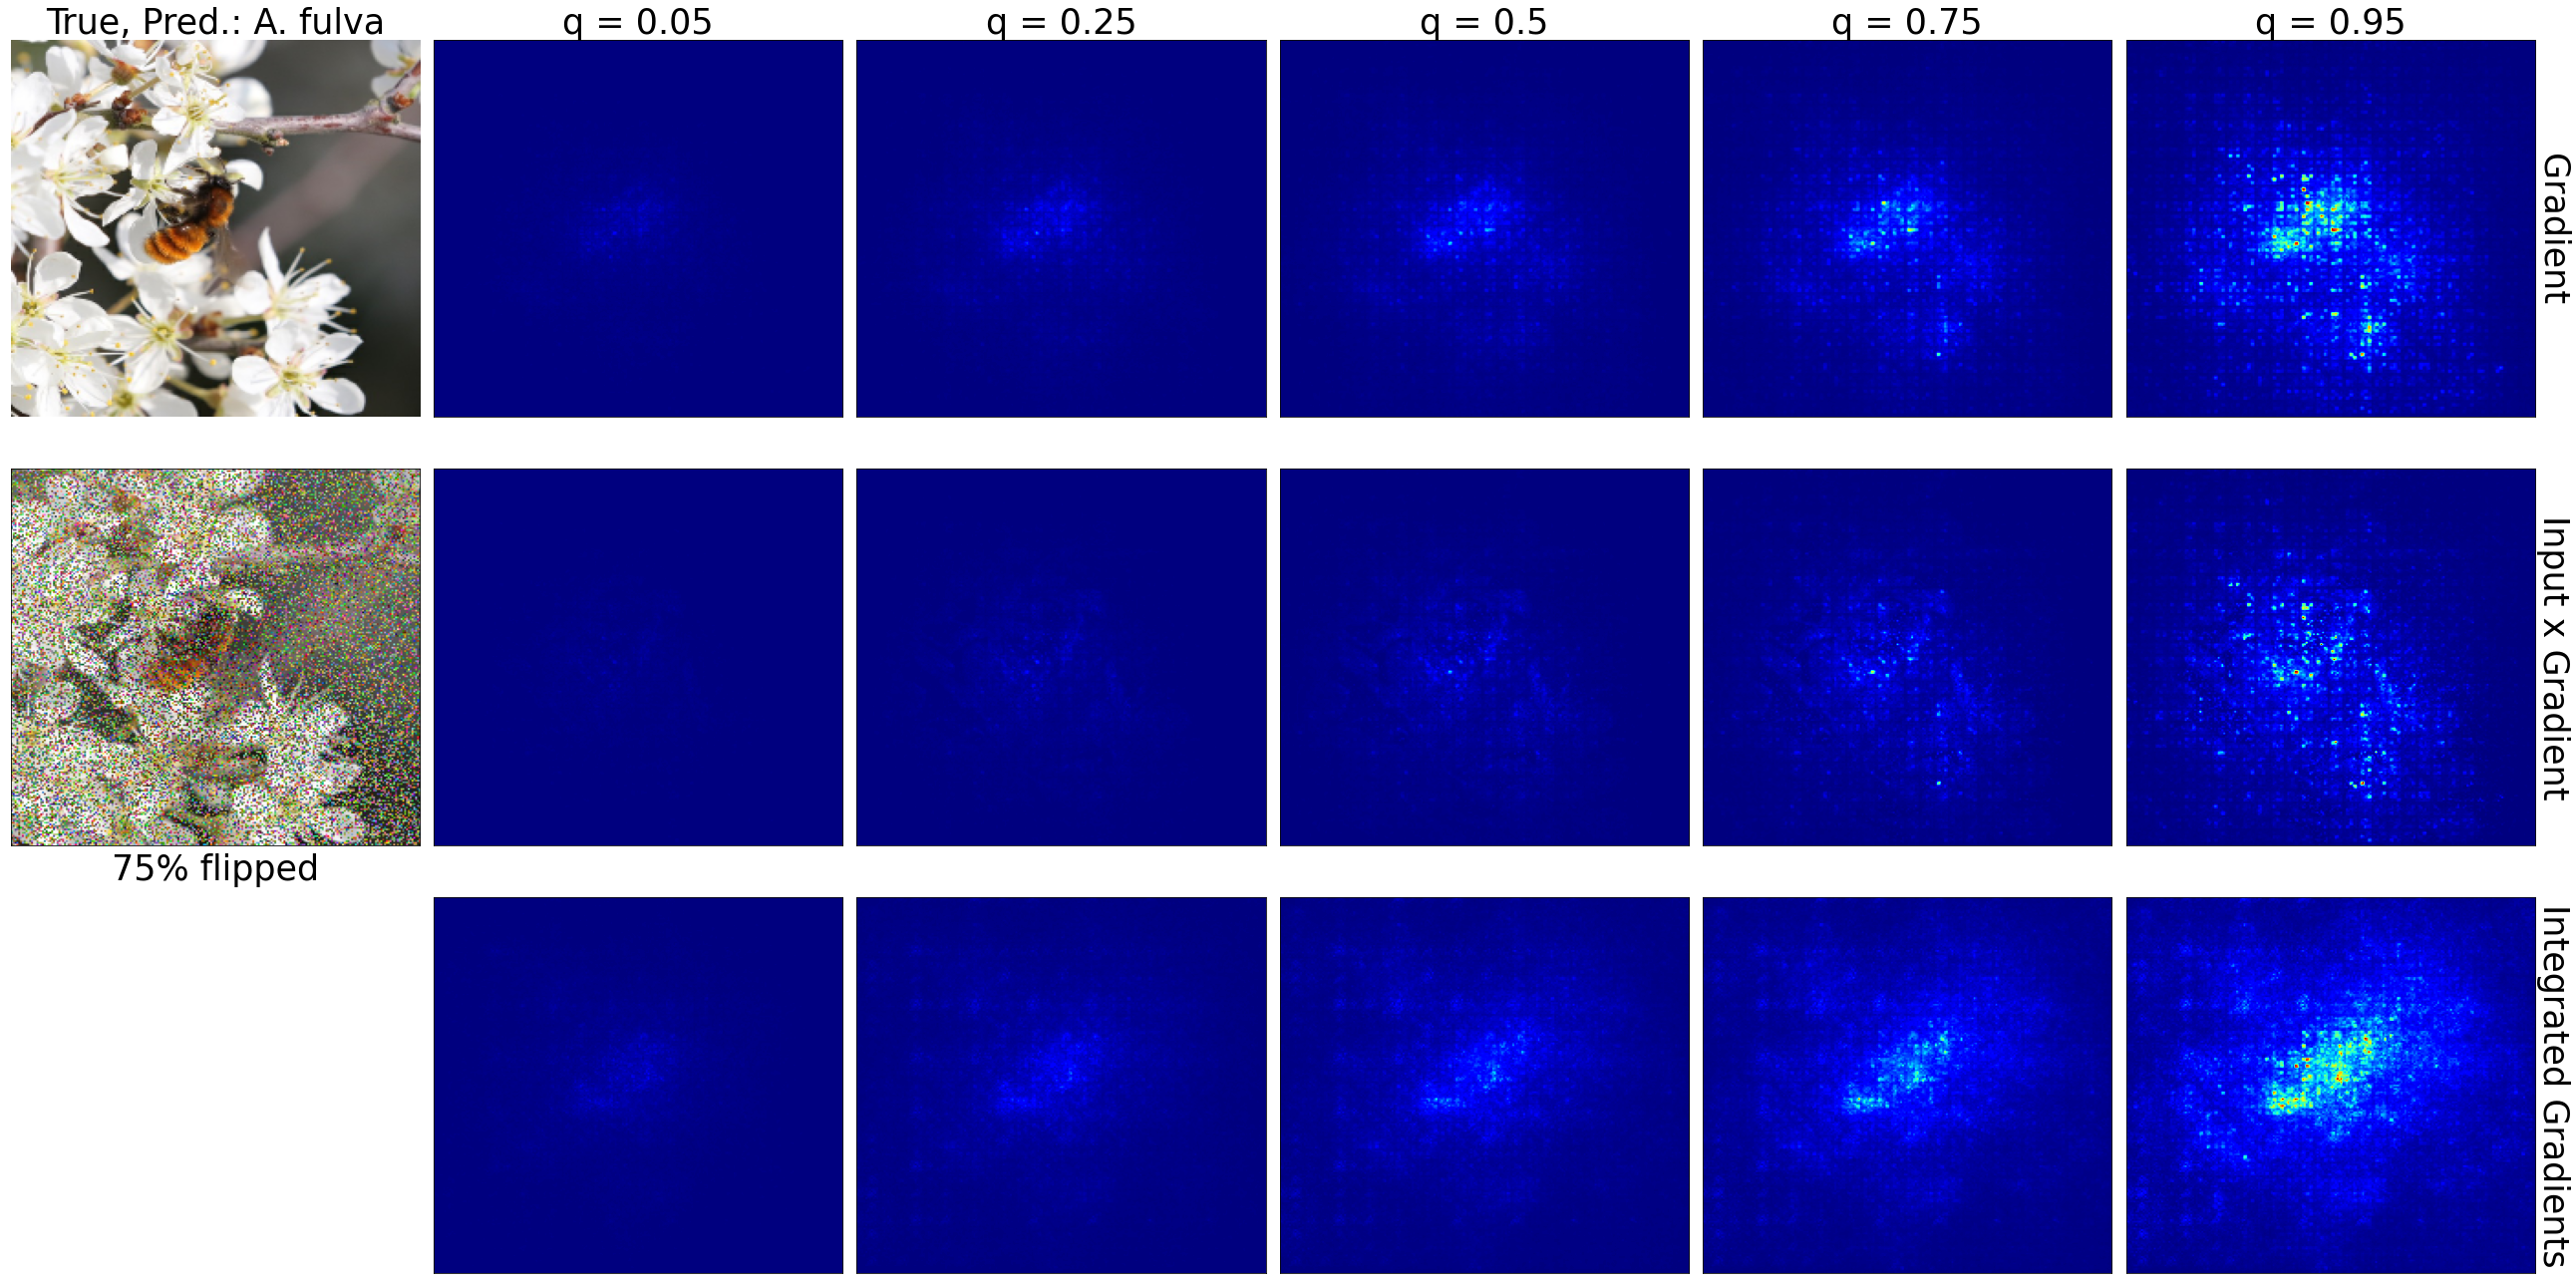

In [74]:
num_cols, num_rows = len(q)+1, len(explainers)
title_size, ticks_size = 35, 35

fig = plt.figure(figsize = (6 * num_cols, 6 * num_rows))

plt.subplot(num_rows, num_cols, 1)
plt.imshow(img, aspect = 'auto')
gen, spec = classes[y_pred].split('_')
title_label = gen[0] + '. ' + spec
plt.title('True, Pred.: ' + title_label, fontsize = title_size)
plt.axis('off')

plt.subplot(num_rows, num_cols, len(q)+2)
plt.imshow(img_flip, aspect = 'auto')
plt.xlabel(str(percents) + '% flipped', fontsize = title_size)
plt.xticks([]);plt.yticks([])

for i in range(num_rows):
    for j in range(num_cols-1):
        ax = plt.subplot(num_rows, num_cols, j+i*num_cols+2)
        plt.imshow(qmaps[expl_names[i]][j], cmap='jet',
                   norm = plt.Normalize(np.min(qmaps[expl_names[i]]), np.max(qmaps[expl_names[i]])),
                   # Note: very important to keep the same normalization across all quantile maps, otherwise very tiny values in the first quantiles get
                   #       stretched out in the colormap and give the wrong impression of high heatmap values!
                   aspect='auto')
        if i == 0:
            plt.title('q = ' + str(q[j]), fontsize = title_size)
        plt.xticks([])
        plt.yticks([])
        if j == num_cols-2:
            ax.yaxis.set_label_position("right")
            ax.set_ylabel(expl_names[i], fontsize = ticks_size, rotation = -90, labelpad = 35)

plt.tight_layout()
fig.savefig(FIGURES_PATH + classes[y_pred] + '_qmaps_pf_rand.png', bbox_inches = 'tight')
plt.show()